# Geospatial machine learning for childhood stunting in Ethiopia — full reproducible analysis (revision)

**Manuscript:** *Geospatial Machine Learning for Predicting Childhood Stunting in Ethiopia: A Spatially Cross-Validated Approach* (PONE-D-26-40790, revised version)

This notebook reproduces every number, table and figure in the revised manuscript, including the analyses added in response to the reviewers:

| Section | Purpose | Reviewer point |
|---|---|---|
| 2 | Sample-derivation flow, survey-weighted vs unweighted prevalence, children per cluster | R1 §2, §3 |
| 3 | Spatial blocks, fold table, fold map, block-number sensitivity | R1 §1 |
| 4 | Fully specified models and hyperparameters | R1 §2 |
| 5 | Random vs **cluster-grouped** vs spatial block CV (imputation fitted inside each training fold) | R1 §1, §2 |
| 6 | Is random forest really better than logistic regression? (K-means seeds, cluster bootstrap) | R1 §1 |
| 7 | **Out-of-fold** classification metrics, precision–recall, calibration | R1 §1, R2 |
| 8 | Child/household vs geospatial vs combined feature sets (same spatial folds) | R1 §4 |
| 9 | Moran's I, LISA, false-discovery-rate correction, cluster-size sensitivity | R1 §3 |
| 10 | Gini, held-out permutation importance and (optional) SHAP | R1 §5 |
| 11 | Export of shareable aggregated outputs | Journal requirements 2–4 |

**How to run in Google Colab:** upload the input files to a Google Drive folder, edit `DATA_DIR` / `OUT_DIR` in Section 0, then *Runtime → Run all*. Set `FAST = True` for a quick smoke test (about 10 minutes) and `FAST = False` for the full analysis (about 45–90 minutes depending on the Colab CPU).

**Data:** DHS microdata cannot be redistributed. Obtain the Ethiopia 2024/25 DHS Children's Recode, the geospatial covariate extract (ETGC8AFL) and the GPS file (ETGE8AFL) from the DHS Program (https://dhsprogram.com/data/) and place them in `DATA_DIR`.

## 0. Setup

In [2]:
# ---- 0.1 Mount Google Drive (Colab) and set paths -------------------------------------------
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:                       # running locally
    IN_COLAB = False

# >>> EDIT THESE TWO PATHS <<<
DATA_DIR = '/content/drive/MyDrive/Stunting_Geospatial'      # folder holding the input files
OUT_DIR  = '/content/drive/MyDrive/Stunting_Geospatial/outputs'   # results are written here
if not IN_COLAB:                           # local fall-back
    DATA_DIR = os.environ.get('DATA_DIR', './data'); OUT_DIR = os.environ.get('OUT_DIR', './outputs')

KR_FILE  = 'CHildrens_3.csv'   # Ethiopia 2024/25 DHS Children's Recode exported to CSV (file name as uploaded)
COV_FILE = 'ETGC8AFL.csv'        # DHS geospatial covariate extract
GPS_FILE = 'ETGE8AFL.dbf'        # DHS GPS file attribute table (ETGE8AFL.shp/.shx/.dbf must sit together)

FAST = False        # True = smoke test (fewer repeats / permutations / bootstraps); False = full analysis
SEED = 42
os.makedirs(OUT_DIR, exist_ok=True)
for f in (KR_FILE, COV_FILE, GPS_FILE):
    assert os.path.exists(os.path.join(DATA_DIR, f)), f'Missing input file: {f} in {DATA_DIR}'
print('Inputs found. Outputs ->', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Inputs found. Outputs -> /content/drive/MyDrive/Stunting_Geospatial/outputs


In [3]:
# ---- 0.2 Install extra packages (Colab already has scikit-learn, xgboost, lightgbm, matplotlib) ---
!pip -q install shap esda libpysal

In [4]:
# ---- 0.3 Imports, versions and seeds -------------------------------------------------------------
import warnings, json, struct, time, platform
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
import sklearn, scipy
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
                             roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
from scipy.spatial import cKDTree
try:
    from xgboost import XGBClassifier; HAVE_XGB = True
except Exception: HAVE_XGB = False
try:
    from lightgbm import LGBMClassifier; HAVE_LGBM = True
except Exception: HAVE_LGBM = False
try:
    import shap; HAVE_SHAP = True
except Exception: HAVE_SHAP = False
np.random.seed(SEED)
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': .3})

versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'scikit-learn': sklearn.__version__, 'matplotlib': matplotlib.__version__}
for mod in ('xgboost', 'lightgbm', 'shap', 'esda', 'libpysal', 'geopandas'):
    try: versions[mod] = __import__(mod).__version__
    except Exception: versions[mod] = 'not installed'
versions['random_seed'] = SEED
json.dump(versions, open(os.path.join(OUT_DIR, 'environment_versions.json'), 'w'), indent=1)
print(versions)
REP = 3 if FAST else 20          # K-means seed repeats (Section 6)
NPERM = 99 if FAST else 999      # permutations for Moran / LISA
NBOOT = 50 if FAST else 1000     # cluster-bootstrap replicates

{'python': '3.13.18', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'shap': '0.54.1', 'esda': '2.9.0', 'libpysal': '4.14.1', 'geopandas': '1.2.0', 'random_seed': 42}


In [5]:
# ---- 0.4 Helper functions ------------------------------------------------------------------------
def read_dbf(path, enc='latin-1'):
    """Minimal dBase reader (avoids needing geopandas just to read the GPS attribute table)."""
    with open(path, 'rb') as f:
        h = f.read(32); n = struct.unpack('<I', h[4:8])[0]; hl, rl = struct.unpack('<HH', h[8:12]); fields = []
        while True:
            d = f.read(32)
            if d[0] == 0x0D: break
            fields.append((d[:11].split(b'\x00')[0].decode(), chr(d[11]), d[16]))
        f.seek(hl); rows = []
        for _ in range(n):
            r = f.read(rl)
            if r[0] == 0x2A: continue
            o = 1; row = []
            for nm, t, l in fields:
                v = r[o:o+l].decode(enc).strip(); o += l
                if t in 'NF':
                    try: v = float(v)
                    except Exception: v = None
                row.append(v)
            rows.append(row)
    return pd.DataFrame(rows, columns=[x[0] for x in fields])

def utm(lat, lon, lon0_deg=39.0):
    """WGS84 -> UTM zone 37N (EPSG:32637), Kruger series. Returns metres."""
    a = 6378137.0; f = 1/298.257223563; k0 = 0.9996; lam0 = np.radians(lon0_deg)
    phi = np.radians(lat); lam = np.radians(lon) - lam0
    n = f/(2-f); A = a/(1+n)*(1+n**2/4+n**4/64)
    al = [n/2-2*n**2/3+5*n**3/16, 13*n**2/48-3*n**3/5, 61*n**3/240]; e = np.sqrt(f*(2-f))
    t = np.sinh(np.arctanh(np.sin(phi)) - e*np.arctanh(e*np.sin(phi)))
    xi = np.arctan2(t, np.cos(lam)); eta = np.arctanh(np.sin(lam)/np.sqrt(1+t**2))
    x = k0*A*(eta + sum(al[j]*np.cos(2*(j+1)*xi)*np.sinh(2*(j+1)*eta) for j in range(3))) + 500000
    y = k0*A*(xi + sum(al[j]*np.sin(2*(j+1)*xi)*np.cosh(2*(j+1)*eta) for j in range(3)))
    return x, y

def svy_ratio(yv, w, strata, psu):
    """Design-based (Taylor-linearised) weighted proportion with strata and PSU (DHS: v022, v021)."""
    z = w*yv; r = z.sum()/w.sum(); u = z - r*w
    df = pd.DataFrame({'u': u, 's': strata, 'p': psu}); v = 0.0
    for _, g in df.groupby('s'):
        t = g.groupby('p').u.sum(); m = len(t)
        if m > 1: v += m/(m-1)*((t-t.mean())**2).sum()
    return r, np.sqrt(v)/w.sum()

def save_table(df, name, index=False):
    df.to_csv(os.path.join(OUT_DIR, name + '.csv'), index=index); return df
def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, name + '.png'), dpi=300); plt.show()

# ---- Ethiopia outline for ALL maps: Natural Earth (public domain) if downloadable, otherwise a built-in simplified outline
ETH_FALLBACK = np.array([[37.91, 14.96], [38.43, 14.59], [38.75, 14.59], [38.98, 14.71], [39.15, 14.74], [39.38, 14.54], [39.99, 14.54], [40.02, 14.45], [40.25, 14.45], [40.91, 14.14], [41.2, 13.77], [41.71, 13.39], [42.05, 12.88], [42.4, 12.57], [42.37, 12.46], [41.79, 11.72], [41.82, 11.1], [41.86, 11.05], [42.38, 11.05], [42.61, 11.11], [42.83, 10.93], [42.72, 10.73], [42.72, 10.42], [43.0, 10.02], [43.0, 9.88], [43.15, 9.85], [43.29, 9.65], [43.29, 9.54], [43.42, 9.5], [43.61, 9.31], [43.62, 9.18], [43.8, 9.18], [44.06, 9.1], [46.97, 8.02], [47.88, 8.01], [45.04, 4.99], [43.71, 4.93], [42.82, 4.23], [42.56, 4.23], [42.18, 4.23], [41.92, 3.92], [41.17, 3.92], [40.91, 4.14], [40.57, 4.14], [40.25, 3.97], [39.99, 3.92], [39.58, 3.41], [39.01, 3.46], [38.75, 3.58], [38.14, 3.58], [36.87, 4.42], [36.12, 4.45], [35.79, 4.78], [35.79, 5.32], [35.27, 5.52], [34.72, 6.54], [34.25, 6.8], [34.06, 7.22], [33.55, 7.68], [33.0, 7.74], [32.93, 7.78], [33.29, 8.39], [33.35, 8.33], [33.73, 8.33], [33.74, 8.43], [33.86, 8.49], [33.94, 8.66], [33.94, 9.65], [34.23, 10.64], [34.72, 10.93], [34.81, 11.32], [35.18, 12.0], [35.88, 12.63], [36.28, 13.62], [36.4, 14.38], [36.55, 14.42], [37.22, 14.28], [37.59, 14.28], [37.91, 14.96]])
def load_boundary():
    try:
        import geopandas as gpd
        for url in ['https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip',
                    'https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip']:
            try:
                w = gpd.read_file(url)
                m = np.zeros(len(w), bool)
                for col in ['ADMIN', 'NAME', 'NAME_EN', 'SOVEREIGNT', 'ISO_A3', 'ADM0_A3']:
                    if col in w.columns: m |= w[col].astype(str).isin(['Ethiopia', 'ETH'])
                if m.sum() > 0:
                    geom = w[m].geometry.unary_union
                    polys = list(geom.geoms) if hasattr(geom, 'geoms') else [geom]
                    rings = [np.array(p.exterior.coords) for p in polys]
                    print('Ethiopia boundary: Natural Earth (public domain) from', url.split('/')[-1]); return rings
            except Exception as e: print('  boundary download failed:', str(e)[:80])
    except Exception as e: print('geopandas not usable:', str(e)[:80])
    print('Ethiopia boundary: built-in simplified outline (Natural Earth 1:110m derived)'); return [ETH_FALLBACK]
ETH_RINGS = load_boundary()

# label positions for regions (median of cluster coordinates); small regions get a leader line to an offset label
LABEL_OFFSET = {'Addis Ababa': (33.3, 9.9), 'Dire Dawa': (45.2, 11.6), 'Harari': (46.4, 10.3)}
LABEL_POS = {'Oromia': (40.9, 8.3), 'Central Ethiopia': (37.3, 8.7)}   # manual positions where the cluster median would sit on top of another region
def draw_eth(ax, regions=None, fs=6.5, color='k'):
    """Draw Ethiopia outline and (optionally) region names. regions = DataFrame with lon, lat, region."""
    for r in ETH_RINGS: ax.plot(r[:, 0], r[:, 1], color=color, lw=1.1, zorder=1)
    ax.set_xlim(32.6, 48.4); ax.set_ylim(2.8, 15.4); ax.set_aspect('equal')
    if regions is not None:
        for reg, g in regions.groupby('region'):
            x, yv = g.lon.median(), g.lat.median()
            if reg in LABEL_POS: x, yv = LABEL_POS[reg]
            if reg in LABEL_OFFSET:
                tx, ty = LABEL_OFFSET[reg]
                ax.annotate(reg, (x, yv), (tx, ty), fontsize=fs, ha='center', va='center', zorder=6, arrowprops=dict(arrowstyle='-', lw=.6, color='k'), bbox=dict(boxstyle='round,pad=.15', fc='white', ec='none', alpha=.8))
            else:
                ax.text(x, yv, reg, fontsize=fs, ha='center', va='center', zorder=6, fontweight='bold', bbox=dict(boxstyle='round,pad=.15', fc='white', ec='none', alpha=.65))
def north_arrow(ax):
    ax.annotate('N', xy=(47.7, 4.6), xytext=(47.7, 3.5), ha='center', fontsize=10, arrowprops=dict(arrowstyle='-|>', color='k'))

Ethiopia boundary: Natural Earth (public domain) from ne_50m_admin_0_countries.zip


## 1. Load data
The Children's Recode is used because it is the DHS file that holds, for every child under five, the anthropometric measurements (`hw70` height-for-age z-score ×100, `hw1` age in months), the sampling weight and design variables (`v005`, `v021`, `v022`), and the household and maternal characteristics (`v106`, `v190`, `v025`) in one record, and it carries the cluster number (`v001`) used to link the GPS and covariate files.

In [6]:
kr  = pd.read_csv(os.path.join(DATA_DIR, KR_FILE), usecols=['caseid','bidx','v001','v005','v021','v022','v024','v025','v106','v190','hw1','hw13','hw70','b5'], low_memory=False)
cov = pd.read_csv(os.path.join(DATA_DIR, COV_FILE))
gps = read_dbf(os.path.join(DATA_DIR, GPS_FILE))

# 31 geospatial predictors: the 2020 layer of each time-varying covariate (latest year in the DHS extract) + time-invariant layers
tv = ['All_Population_Count','Aridity','Day_Land_Surface_Temp','Diurnal_Temperature_Range','Enhanced_Vegetation_Index','Frost_Days','ITN_Coverage',
      'Land_Surface_Temperature','Malaria_Incidence','Malaria_Prevalence','Maximum_Temperature','Mean_Temperature','Minimum_Temperature',
      'Night_Land_Surface_Temp','PET','Precipitation','Rainfall','U5_Population','UN_Population_Density']
GEO = [t + '_2020' for t in tv] + ['Drought_Episodes','Elevation','Global_Human_Footprint','Growing_Season_Length','Irrigation',
        'Livestock_Cattle','Livestock_Chickens','Livestock_Goats','Livestock_Pigs','Livestock_Sheep','Nightlights_Composite','Travel_Times']
HH  = ['v106','v190','v025','hw1']          # maternal education, wealth quintile, residence, child age (months)
assert len(GEO) == 31 and all(c in cov.columns for c in GEO)
print('Children recode:', kr.shape, '| covariate file:', cov.shape, '| GPS clusters:', gps.shape[0])

Children recode: (13565, 14) | covariate file: (797, 135) | GPS clusters: 797


## 2. Analytical sample, survey design and cluster sizes  *(Reviewer 1, comments 2 and 3)*

In [7]:
# ---- 2.1 Sample-derivation flow ---------------------------------------------------------------
alive   = kr[kr.b5 == 1]                          # child alive at interview
in_anth = alive[alive.hw1.notna()]                # in the household subsample selected for height/weight measurement
haz_rec = in_anth[in_anth.hw70.notna()]           # a height-for-age z-score was recorded
final   = haz_rec[haz_rec.hw70.between(-600, 600)]  # biologically plausible HAZ (DHS flag 9998 / out-of-range removed)
flow = pd.DataFrame([
    ['Births in Children\'s Recode', len(kr), None],
    ['  Not alive at interview', int((kr.b5 == 0).sum()), len(alive)],
    ['  Alive but not in the anthropometry subsample', len(alive)-len(in_anth), len(in_anth)],
    ['  In subsample but no HAZ recorded (absent/refused/other)', len(in_anth)-len(haz_rec), len(haz_rec)],
    ['  HAZ flagged / biologically implausible (outside -6 to +6 SD)', len(haz_rec)-len(final), len(final)],
    ['Final analytical sample (children 0-59 months)', len(final), len(final)]],
    columns=['Step', 'Excluded / n', 'Remaining'])
display(save_table(flow, 'Table_S1_sample_flow'))

s = final.copy(); s['stunted'] = (s.hw70 < -200).astype(int)          # HAZ < -2 SD
cl = cov[['DHSCLUST'] + GEO].merge(gps[['DHSCLUST','LATNUM','LONGNUM','URBAN_RURA','ADM1NAME','DHSREGNA']], on='DHSCLUST')
cl['x'], cl['y'] = utm(cl.LATNUM.values, cl.LONGNUM.values)
d = s.merge(cl, left_on='v001', right_on='DHSCLUST', how='left').reset_index(drop=True)
y = d.stunted.values; X = d[GEO + HH]; XY = d[['x','y']] / 1000.0
print('Analytical sample:', len(d), 'children in', d.v001.nunique(), 'of', len(cl), 'GPS clusters')

,Step,Excluded / n,Remaining
0,Births in Children's Recode,13565,NaN
1,Not alive at interview,644,12921.0
2,Alive but not in the anthropometry subsample,6647,6274.0
3,In subsample but no HAZ recorded (absent/ref...,347,5927.0
4,HAZ flagged / biologically implausible (outs...,84,5843.0
5,Final analytical sample (children 0-59 months),5843,5843.0


Analytical sample: 5843 children in 787 of 797 GPS clusters


In [8]:
# ---- 2.2 Weighted vs unweighted prevalence ---------------------------------------------------
w = d.v005 / 1e6
pw, sew = svy_ratio(y, w, d.v022, d.v021); pu = y.mean(); seu = np.sqrt(pu*(1-pu)/len(y))
prev = pd.DataFrame([['Unweighted (simple proportion)', 100*pu, 100*(pu-1.96*seu), 100*(pu+1.96*seu)],
                     ['Survey-weighted (v005; strata v022; PSU v021; Taylor linearisation)', 100*pw, 100*(pw-1.96*sew), 100*(pw+1.96*sew)]],
                    columns=['Estimate', 'Prevalence %', 'CI low', 'CI high']).round(1)
display(save_table(prev, 'Table_S2_prevalence'))
print('NOTE: the ML and spatial analyses below are unweighted (individual-level classification / cluster-level mapping).')

# ---- 2.3 Children per cluster -----------------------------------------------------------------
cn = d.groupby('v001').agg(n=('stunted','size'), k=('stunted','sum')); cn['prev'] = cn.k / cn.n
print('Clusters with >=1 valid child:', len(cn), '| GPS clusters with none:', len(cl)-len(cn))
print(cn.n.describe().round(1).to_string())
print('Clusters with <5 children:', int((cn.n<5).sum()), '| <10:', int((cn.n<10).sum()), '| >=10:', int((cn.n>=10).sum()))
RES = {}   # numbers collected for the final summary cell
RES['clusters_used'] = len(cn); RES['clusters_gps'] = len(cl); RES['cluster_median_n'] = float(cn.n.median()); RES['cluster_iqr'] = (float(cn.n.quantile(.25)), float(cn.n.quantile(.75)))

,Estimate,Prevalence %,CI low,CI high
0,Unweighted (simple proportion),37.7,36.5,39.0
1,Survey-weighted (v005; strata v022; PSU v021; ...,39.9,37.5,42.2


NOTE: the ML and spatial analyses below are unweighted (individual-level classification / cluster-level mapping).
Clusters with >=1 valid child: 787 | GPS clusters with none: 10
count    787.0
mean       7.4
std        4.1
min        1.0
25%        5.0
50%        7.0
75%        9.0
max       27.0
Clusters with <5 children: 192 | <10: 591 | >=10: 196


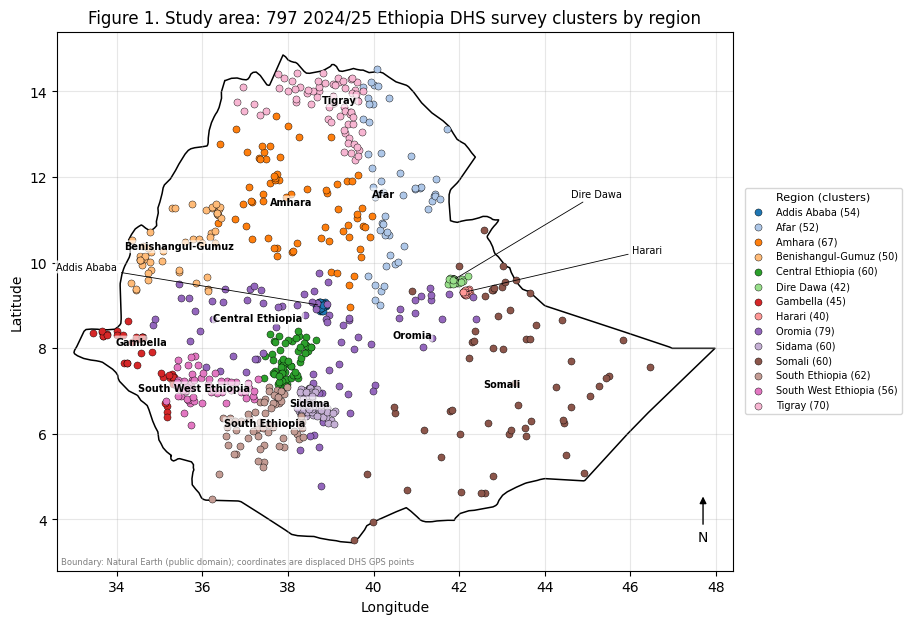

region    Addis Ababa  Afar  Amhara  Benishangul-Gumuz  Central Ethiopia  Dire Dawa  Gambella  Harari  Oromia  Sidama  Somali  South Ethiopia  South West Ethiopia  Tigray
clusters           54    52      67                 50                60         42        45      40      79      60      60              62                   56      70


In [9]:
# ---- FIGURE 1. Study area: all DHS survey clusters coloured and labelled by region ------------------------------
regdf = cl.rename(columns={'LONGNUM': 'lon', 'LATNUM': 'lat', 'DHSREGNA': 'region'})
regions_sorted = sorted(regdf.region.unique()); cmap20 = plt.get_cmap('tab20')
fig, ax = plt.subplots(figsize=(9, 7))
for i, rg in enumerate(regions_sorted):
    t = regdf[regdf.region == rg]; ax.scatter(t.lon, t.lat, s=26, color=cmap20(i % 20), edgecolor='k', linewidth=.3, zorder=3, label=f'{rg} ({len(t)})')
draw_eth(ax, regdf, fs=7); north_arrow(ax)
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_title(f'Figure 1. Study area: {len(cl)} 2024/25 Ethiopia DHS survey clusters by region')
ax.legend(title='Region (clusters)', fontsize=7, title_fontsize=8, loc='center left', bbox_to_anchor=(1.01, .5)); ax.text(32.7, 2.95, 'Boundary: Natural Earth (public domain); coordinates are displaced DHS GPS points', fontsize=6, color='gray')
save_fig('Fig1_study_area_clusters_by_region')
print(regdf.groupby('region').size().rename('clusters').to_frame().T.to_string())

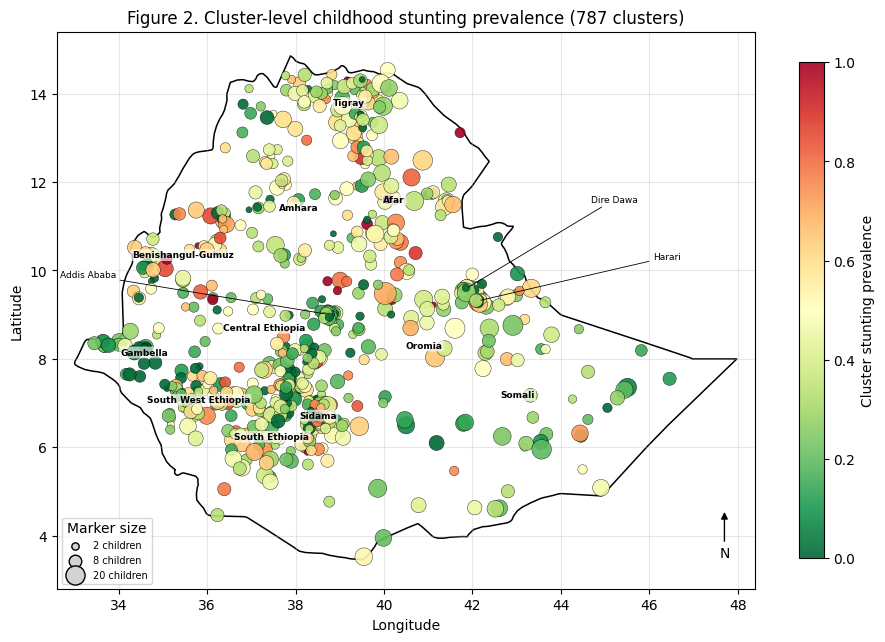

In [10]:
# ---- FIGURE 2. Cluster-level stunting prevalence (marker size = number of children) -----------------------------
c2 = cc_tmp = cl.merge(cn.reset_index().rename(columns={'v001': 'DHSCLUST'}), on='DHSCLUST', how='inner').rename(columns={'LONGNUM': 'lon', 'LATNUM': 'lat', 'DHSREGNA': 'region'})
fig, ax = plt.subplots(figsize=(9.5, 7)); draw_eth(ax, c2, fs=6.5); north_arrow(ax)
sc = ax.scatter(c2.lon, c2.lat, c=c2.prev, s=10 + 9*c2.n, cmap='RdYlGn_r', vmin=0, vmax=1, edgecolor='k', linewidth=.3, alpha=.9, zorder=4)
cb = plt.colorbar(sc, ax=ax, shrink=.75); cb.set_label('Cluster stunting prevalence')
for n_ in (2, 8, 20): ax.scatter([], [], s=10 + 9*n_, color='lightgray', edgecolor='k', label=f'{n_} children')
ax.legend(title='Marker size', fontsize=7, loc='lower left'); ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title(f'Figure 2. Cluster-level childhood stunting prevalence ({len(c2)} clusters)'); save_fig('Fig2_cluster_prevalence_map')

## 3. Spatial blocks and folds  *(Reviewer 1, comment 1)*
Children are partitioned into 10 compact blocks by K-means on UTM zone 37N coordinates; blocks are then assigned to 5 folds with `GroupKFold`. The *same* fold indices are used for every model and every feature set. Cluster-grouped random CV (`StratifiedGroupKFold`) keeps all children of a DHS cluster together without creating geographic blocks.

Number of DHS clusters appearing in BOTH training and test data:


,Random (child-level),Cluster-grouped random,Spatial block (k=10)
Fold 1,555,0,0
Fold 2,568,0,0
Fold 3,577,0,0
Fold 4,562,0,0
Fold 5,565,0,0


,fold,blocks,clusters,children,stunted,prevalence_pct
0,1,"0, 9",170,1250,417,33.4
1,2,"4, 8",137,1147,401,35.0
2,3,"6, 7",155,1097,481,43.8
3,4,"3, 5",154,1158,432,37.3
4,5,"1, 2",171,1191,473,39.7


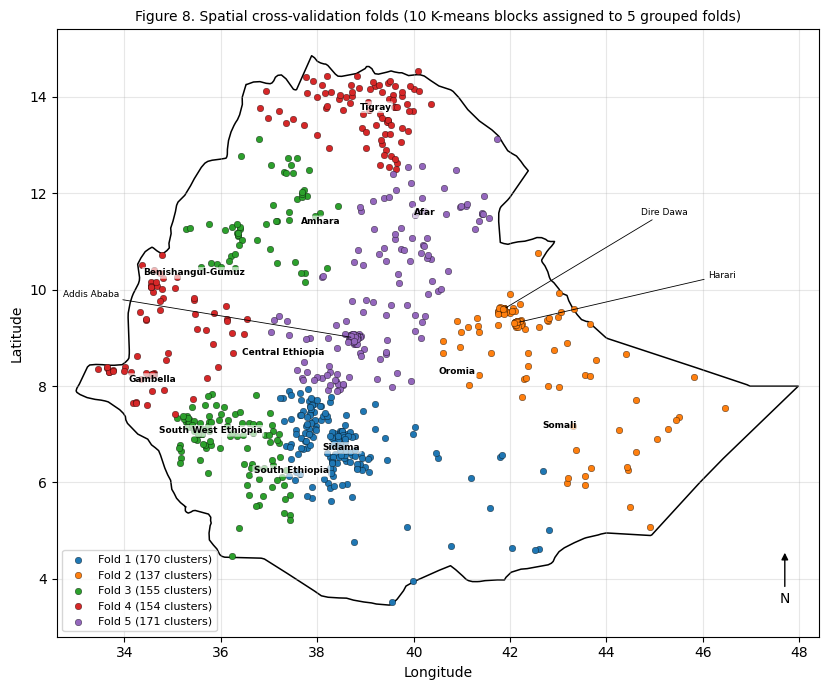

In [11]:
def spatial_groups(k=10, seed=SEED):
    return KMeans(k, random_state=seed, n_init=10).fit(d[['x','y']]).labels_

blocks = spatial_groups(10); d['block'] = blocks
SCH = {'Random (child-level)':   list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, y)),
       'Cluster-grouped random': list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, d.v001)),
       'Spatial block (k=10)':   list(GroupKFold(5).split(X, y, blocks))}

# clusters shared between training and test sets (information-leakage check)
ov = pd.DataFrame({k: [len(set(d.v001.iloc[tr]) & set(d.v001.iloc[te])) for tr, te in sp] for k, sp in SCH.items()}, index=[f'Fold {i}' for i in range(1,6)])
print('Number of DHS clusters appearing in BOTH training and test data:'); display(save_table(ov, 'Table_S3_cluster_overlap', index=True))

rows = []
for i, (tr, te) in enumerate(SCH['Spatial block (k=10)']):
    t = d.iloc[te]
    rows.append(dict(fold=i+1, blocks=', '.join(map(str, sorted(t.block.unique()))), clusters=t.v001.nunique(), children=len(te), stunted=int(t.stunted.sum()), prevalence_pct=round(100*t.stunted.mean(), 1)))
foldtab = save_table(pd.DataFrame(rows), 'Table_S4_spatial_fold_description'); display(foldtab)

fold_of = np.zeros(len(d), int)
for i, (tr, te) in enumerate(SCH['Spatial block (k=10)']): fold_of[te] = i+1
d['fold'] = fold_of
cf = d.groupby('v001').agg(lon=('LONGNUM','first'), lat=('LATNUM','first'), fold=('fold','first'), region=('DHSREGNA','first'))
fig, ax = plt.subplots(figsize=(9, 7)); cm = plt.get_cmap('tab10'); draw_eth(ax, cf, fs=6.5); north_arrow(ax)
for f in range(1, 6):
    t = cf[cf.fold == f]; ax.scatter(t.lon, t.lat, s=22, color=cm(f-1), edgecolor='k', linewidth=.25, zorder=4, label=f'Fold {f} ({len(t)} clusters)')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.legend(fontsize=8, loc='lower left')
ax.set_title('Figure 8. Spatial cross-validation folds (10 K-means blocks assigned to 5 grouped folds)', fontsize=10); save_fig('Fig8_spatial_folds')

## 4. Models and fully specified hyperparameters  *(Reviewer 1, comment 2)*
Hyperparameters are **fixed a priori** (not tuned) so that differences between validation designs are not confounded with model selection. Median imputation is part of each scikit-learn `Pipeline`, so imputation values are always learned from the training fold only.

In [12]:
def make(name, seed=SEED):
    imp = SimpleImputer(strategy='median')
    if name == 'Logistic regression':   return make_pipeline(imp, StandardScaler(), LogisticRegression(max_iter=2000, C=1.0))
    if name == 'Random forest':         return make_pipeline(imp, RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=seed, n_jobs=-1))
    if name == 'Gradient boosting':     return make_pipeline(imp, GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=seed))
    if name == 'XGBoost':               return make_pipeline(imp, XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=seed, n_jobs=-1))
    if name == 'LightGBM':              return make_pipeline(imp, LGBMClassifier(n_estimators=300, num_leaves=15, learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, min_child_samples=20, random_state=seed, n_jobs=-1, verbose=-1))
    if name == 'KNN (spatial-only)':    return KNeighborsClassifier(n_neighbors=50)     # inputs: UTM easting/northing in km
    raise ValueError(name)

MODELS = ['Random forest', 'Logistic regression', 'XGBoost', 'Gradient boosting', 'LightGBM', 'KNN (spatial-only)']
if not HAVE_XGB:  MODELS.remove('XGBoost');  print('xgboost not available - skipped')
if not HAVE_LGBM: MODELS.remove('LightGBM'); print('lightgbm not available - skipped')

hp = pd.DataFrame([
 ['Logistic regression', 'median impute -> standardise -> L2 logistic regression; C=1.0, max_iter=2000', 'child/household + geospatial (35)'],
 ['Random forest', '300 trees; max_depth=8; min_samples_leaf=10; class_weight=balanced; random_state=42', '35'],
 ['XGBoost', '300 trees; max_depth=4; learning_rate=0.05; subsample=0.8; colsample_bytree=0.8; random_state=42', '35'],
 ['Gradient boosting', '200 trees; max_depth=3; learning_rate=0.05; subsample=0.8; random_state=42', '35'],
 ['LightGBM', '300 trees; num_leaves=15; learning_rate=0.05; subsample=0.8 (every iteration); colsample_bytree=0.8; min_child_samples=20; random_state=42', '35'],
 ['KNN (spatial-only)', 'k=50 neighbours, Euclidean distance on UTM 37N easting/northing (km)', 'coordinates only (2)']], columns=['Model', 'Fixed settings', 'Inputs'])
display(save_table(hp, 'Table_S5_hyperparameters'))

def evaluate(name, splits, cols=None, return_oof=False):
    XX = XY if name.startswith('KNN') else (X if cols is None else d[cols])
    oof = np.full(len(d), np.nan); aucs = []
    for tr, te in splits:
        m = make(name).fit(XX.iloc[tr], y[tr]); p = m.predict_proba(XX.iloc[te])[:, 1]; oof[te] = p; aucs.append(roc_auc_score(y[te], p))
    return (aucs, oof) if return_oof else aucs

,Model,Fixed settings,Inputs
0,Logistic regression,median impute -> standardise -> L2 logistic re...,child/household + geospatial (35)
1,Random forest,300 trees; max_depth=8; min_samples_leaf=10; c...,35
2,XGBoost,300 trees; max_depth=4; learning_rate=0.05; su...,35
3,Gradient boosting,200 trees; max_depth=3; learning_rate=0.05; su...,35
4,LightGBM,300 trees; num_leaves=15; learning_rate=0.05; ...,35
5,KNN (spatial-only),"k=50 neighbours, Euclidean distance on UTM 37N...",coordinates only (2)


## 5. Random vs cluster-grouped vs spatial block cross-validation  *(Reviewer 1, comment 1)*

Random (child-level)       Random forest        0.717 +/- 0.015
Random (child-level)       Logistic regression  0.684 +/- 0.017
Random (child-level)       XGBoost              0.720 +/- 0.010
Random (child-level)       Gradient boosting    0.724 +/- 0.012
Random (child-level)       LightGBM             0.719 +/- 0.012
Random (child-level)       KNN (spatial-only)   0.618 +/- 0.014
Cluster-grouped random     Random forest        0.687 +/- 0.015
Cluster-grouped random     Logistic regression  0.680 +/- 0.012
Cluster-grouped random     XGBoost              0.694 +/- 0.010
Cluster-grouped random     Gradient boosting    0.694 +/- 0.011
Cluster-grouped random     LightGBM             0.692 +/- 0.005
Cluster-grouped random     KNN (spatial-only)   0.602 +/- 0.008
Spatial block (k=10)       Random forest        0.670 +/- 0.028
Spatial block (k=10)       Logistic regression  0.665 +/- 0.029
Spatial block (k=10)       XGBoost              0.656 +/- 0.030
Spatial block (k=10)       Gradient boos

scheme,Cluster-grouped random,Random (child-level),Spatial block (k=10),Delta random-spatial,Delta random-cluster
model,,,,,
Random forest,0.687 ± 0.015,0.717 ± 0.015,0.670 ± 0.028,0.047,0.030
Logistic regression,0.680 ± 0.012,0.684 ± 0.017,0.665 ± 0.029,0.018,0.003
XGBoost,0.694 ± 0.010,0.720 ± 0.010,0.656 ± 0.030,0.064,0.026
Gradient boosting,0.694 ± 0.011,0.724 ± 0.012,0.656 ± 0.032,0.068,0.030
LightGBM,0.692 ± 0.005,0.719 ± 0.012,0.655 ± 0.022,0.064,0.027
KNN (spatial-only),0.602 ± 0.008,0.618 ± 0.014,0.566 ± 0.054,0.052,0.016


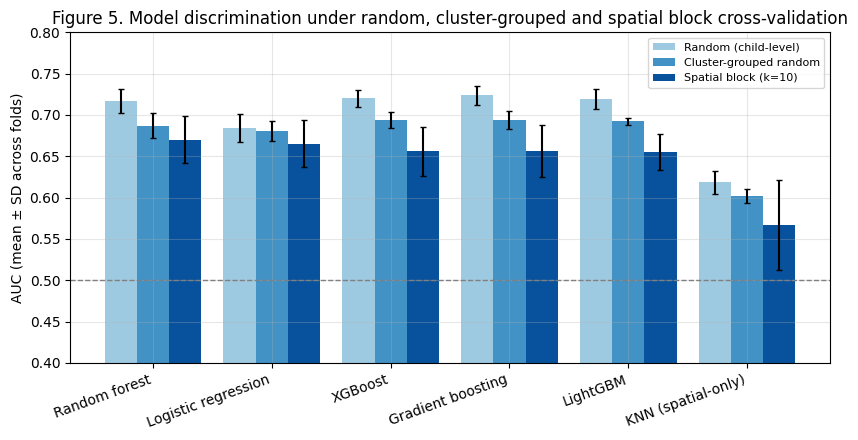

In [13]:
res = []; OOF = {}
for sch, sp in SCH.items():
    for m in MODELS:
        a, oof = evaluate(m, sp, return_oof=True); OOF[(sch, m)] = oof
        res.append(dict(scheme=sch, model=m, mean=np.mean(a), sd=np.std(a, ddof=1), folds=a)); print(f'{sch:26s} {m:20s} {np.mean(a):.3f} +/- {np.std(a, ddof=1):.3f}', flush=True)
cvtab = pd.DataFrame(res)
tab = cvtab.assign(v=lambda t: t['mean'].map('{:.3f}'.format) + ' ± ' + t['sd'].map('{:.3f}'.format)).pivot(index='model', columns='scheme', values='v').loc[MODELS]
tab['Delta random-spatial'] = [cvtab[(cvtab.model==m)&(cvtab.scheme=='Random (child-level)')]['mean'].iloc[0] - cvtab[(cvtab.model==m)&(cvtab.scheme=='Spatial block (k=10)')]['mean'].iloc[0] for m in MODELS]
tab['Delta random-cluster'] = [cvtab[(cvtab.model==m)&(cvtab.scheme=='Random (child-level)')]['mean'].iloc[0] - cvtab[(cvtab.model==m)&(cvtab.scheme=='Cluster-grouped random')]['mean'].iloc[0] for m in MODELS]
display(save_table(tab.round(3), 'Table_1_2_cv_schemes', index=True))
cvtab.drop(columns='folds').to_csv(os.path.join(OUT_DIR, 'cv_summary_long.csv'), index=False)

fig, ax = plt.subplots(figsize=(8.5, 4.5)); wd = .27
for j, (sch, c) in enumerate(zip(SCH, ['#9ecae1', '#4292c6', '#08519c'])):
    t = cvtab[cvtab.scheme == sch].set_index('model').loc[MODELS]; ax.bar(np.arange(len(MODELS)) + (j-1)*wd, t['mean'], wd, yerr=t['sd'], capsize=2, color=c, label=sch)
ax.set_xticks(range(len(MODELS))); ax.set_xticklabels(MODELS, rotation=20, ha='right'); ax.set_ylim(.4, .8); ax.set_ylabel('AUC (mean ± SD across folds)'); ax.legend(fontsize=8)
ax.axhline(.5, color='gray', ls='--', lw=1); ax.set_title('Figure 5. Model discrimination under random, cluster-grouped and spatial block cross-validation'); save_fig('Fig5_cv_comparison')

## 6. Is random forest really better than logistic regression?  *(Reviewer 1, comment 1)*
The spatial-CV AUC difference is tiny. We (i) repeat the block construction with different K-means seeds and (ii) bootstrap clusters to put a confidence interval on the pooled out-of-fold AUC difference.

In [14]:
rng = np.random.default_rng(SEED); uc = d.v001.unique(); idx = {c: np.where(d.v001.values == c)[0] for c in uc}
def boot_idx():
    ch = rng.choice(uc, len(uc)); return np.concatenate([idx[c] for c in ch])
o_rf = OOF[('Spatial block (k=10)', 'Random forest')]; o_lr = OOF[('Spatial block (k=10)', 'Logistic regression')]
diffs = [];
for _ in range(NBOOT):
    ii = boot_idx()
    if len(np.unique(y[ii])) > 1: diffs.append(roc_auc_score(y[ii], o_rf[ii]) - roc_auc_score(y[ii], o_lr[ii]))
RES['rf_lr_diff'] = (roc_auc_score(y, o_rf)-roc_auc_score(y, o_lr), *np.percentile(diffs, [2.5, 97.5])); RES['pooled_auc'] = (roc_auc_score(y, o_rf), roc_auc_score(y, o_lr))
print('Pooled out-of-fold AUC  RF = %.3f, LR = %.3f, difference = %.3f (95%% cluster-bootstrap CI %.3f to %.3f)' % (roc_auc_score(y, o_rf), roc_auc_score(y, o_lr), roc_auc_score(y, o_rf)-roc_auc_score(y, o_lr), *np.percentile(diffs, [2.5, 97.5])))

sens = []
for sd in range(REP):
    g = spatial_groups(10, sd); sp = list(GroupKFold(5).split(X, y, g))
    a1 = np.mean(evaluate('Random forest', sp)); a2 = np.mean(evaluate('Logistic regression', sp)); sens.append((sd, a1, a2, a1-a2))
sens = save_table(pd.DataFrame(sens, columns=['kmeans_seed', 'RF_AUC', 'LR_AUC', 'difference']), 'Table_S6_kmeans_seed_sensitivity')
print(sens.describe().round(4).to_string()); print('RF better than LR in', int((sens['difference'] > 0).sum()), 'of', len(sens), 'K-means seeds')

# number of blocks
bs = []
for k in [5, 10, 15, 20]:
    sp = list(GroupKFold(5).split(X, y, spatial_groups(k)))
    for m in ['Random forest', 'Logistic regression']:
        a = evaluate(m, sp); bs.append(dict(blocks=k, model=m, mean_AUC=np.mean(a), sd=np.std(a, ddof=1)))
display(save_table(pd.DataFrame(bs).round(3), 'Table_S7_block_number_sensitivity'))

Pooled out-of-fold AUC  RF = 0.661, LR = 0.665, difference = -0.005 (95% cluster-bootstrap CI -0.019 to 0.010)
       kmeans_seed   RF_AUC   LR_AUC  difference
count      20.0000  20.0000  20.0000     20.0000
mean        9.5000   0.6604   0.6610     -0.0006
std         5.9161   0.0029   0.0018      0.0016
min         0.0000   0.6583   0.6596     -0.0022
25%         4.7500   0.6588   0.6596     -0.0014
50%         9.5000   0.6597   0.6603     -0.0007
75%        14.2500   0.6606   0.6611     -0.0005
max        19.0000   0.6701   0.6651      0.0055
RF better than LR in 2 of 20 K-means seeds


,blocks,model,mean_AUC,sd
0,5,Random forest,0.656,0.034
1,5,Logistic regression,0.659,0.050
2,10,Random forest,0.670,0.028
3,10,Logistic regression,0.665,0.029
4,15,Random forest,0.665,0.030
5,15,Logistic regression,0.654,0.014
6,20,Random forest,0.667,0.028
7,20,Logistic regression,0.662,0.037


## 7. Out-of-fold classification metrics, precision–recall and calibration  *(Reviewer 1, comment 1; Reviewer 2)*
Metrics are computed from the **out-of-fold spatial-CV predictions** of the random forest and compared with the in-sample values from the model re-fitted to all data (previous Figure 6).

,setting,threshold,sensitivity,specificity,PPV,NPV,accuracy,TP,FP,TN,FN
0,"Out-of-fold (spatial CV), threshold 0.5 [pre-s...",0.500,0.631,0.613,0.497,0.733,0.620,1390,1409,2230,814
1,"Out-of-fold (spatial CV), prevalence-matched t...",0.547,0.505,0.700,0.504,0.700,0.626,1112,1093,2546,1092
2,"Out-of-fold (spatial CV), Youden threshold [po...",0.442,0.762,0.504,0.482,0.778,0.601,1680,1805,1834,524
3,"In-sample (model re-fitted to all 5,843 childr...",0.500,0.801,0.644,0.577,0.843,0.704,1766,1294,2345,438


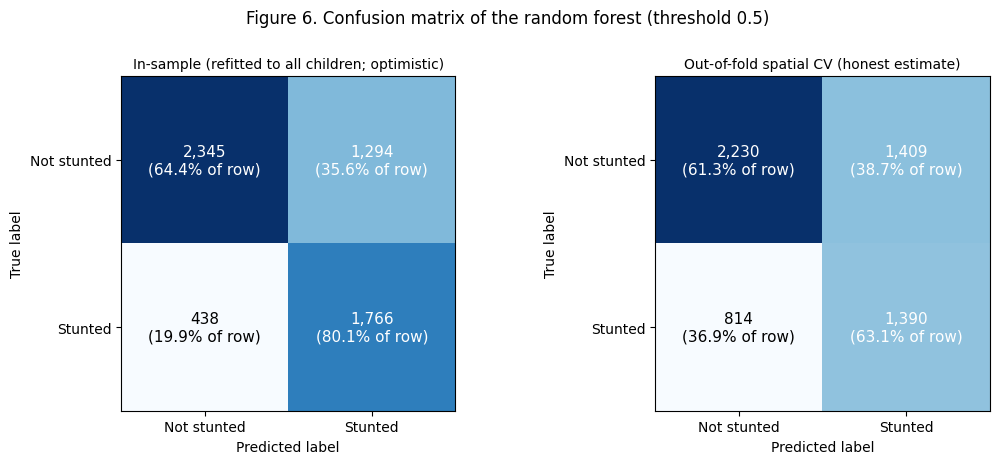

95% CI (cluster bootstrap) at 0.5  sens/spec/PPV/acc: [[0.594, 0.668], [0.585, 0.638], [0.473, 0.52], [0.605, 0.635]]
Out-of-fold: AUC=0.661  PR-AUC (average precision)=0.487 (prevalence 0.377)  Brier=0.226  calibration slope=1.21, intercept=-0.40


,mean_predicted,observed,n
decile,,,
0,0.251,0.135,585
1,0.324,0.175,584
2,0.367,0.265,584
3,0.415,0.312,584
4,0.464,0.422,585
5,0.515,0.455,584
6,0.555,0.488,584
7,0.586,0.515,585
8,0.607,0.477,583


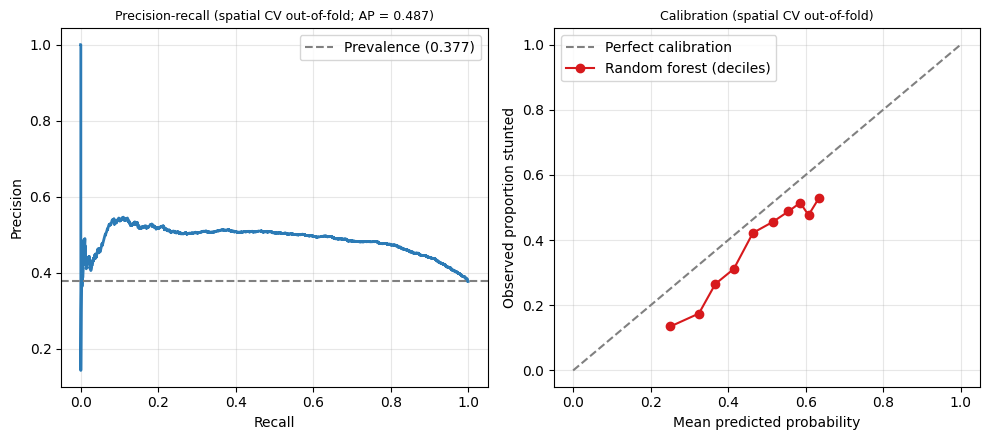

In [15]:
def cls(p, thr, yy=None):
    yy = y if yy is None else yy; pr = (p >= thr).astype(int); tn, fp, fn, tp = confusion_matrix(yy, pr).ravel()
    return dict(threshold=round(float(thr), 3), sensitivity=tp/(tp+fn), specificity=tn/(tn+fp), PPV=tp/(tp+fp), NPV=tn/(tn+fn), accuracy=(tp+tn)/len(yy), TP=tp, FP=fp, TN=tn, FN=fn)
fpr, tpr, th = roc_curve(y, o_rf); youden = th[np.argmax(tpr - fpr)]
full_model = make('Random forest').fit(X, y); p_in = full_model.predict_proba(X)[:, 1]
rows = [('Out-of-fold (spatial CV), threshold 0.5 [pre-specified]', cls(o_rf, .5)),
        ('Out-of-fold (spatial CV), prevalence-matched threshold', cls(o_rf, np.quantile(o_rf, 1 - y.mean()))),
        ('Out-of-fold (spatial CV), Youden threshold [post hoc]', cls(o_rf, youden)),
        ('In-sample (model re-fitted to all 5,843 children), threshold 0.5', cls(p_in, .5))]
ctab = pd.DataFrame([dict(setting=n, **v) for n, v in rows]); display(save_table(ctab.round(3), 'Table_3_classification_metrics'))
# ---- FIGURE 6. Confusion matrices: in-sample (model refitted to all 5,843 children) vs out-of-fold spatial CV
fig, axs = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (ttl, pp) in zip(axs, [('In-sample (refitted to all children; optimistic)', p_in), ('Out-of-fold spatial CV (honest estimate)', o_rf)]):
    cmx = confusion_matrix(y, (pp >= .5).astype(int)); im = ax.imshow(cmx, cmap='Blues'); ax.grid(False)
    for i in range(2):
        for j in range(2): ax.text(j, i, f'{cmx[i, j]:,}\n({100*cmx[i, j]/cmx[i].sum():.1f}% of row)', ha='center', va='center', color='white' if cmx[i, j] > cmx.max()/2 else 'black', fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['Not stunted', 'Stunted']); ax.set_yticks([0, 1]); ax.set_yticklabels(['Not stunted', 'Stunted']); ax.set_xlabel('Predicted label'); ax.set_ylabel('True label'); ax.set_title(ttl, fontsize=10)
fig.suptitle('Figure 6. Confusion matrix of the random forest (threshold 0.5)', y=1.0); save_fig('Fig6_confusion_matrices')

# cluster-bootstrap 95% CI for the pre-specified threshold
bb = []
for _ in range(NBOOT):
    ii = boot_idx(); r = cls(o_rf[ii], .5, y[ii]); bb.append([r['sensitivity'], r['specificity'], r['PPV'], r['accuracy']])
print('95% CI (cluster bootstrap) at 0.5  sens/spec/PPV/acc:', np.round(np.percentile(bb, [2.5, 97.5], axis=0).T, 3).tolist())

ap = average_precision_score(y, o_rf); brier = brier_score_loss(y, o_rf)
cal = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(o_rf/(1-o_rf)).reshape(-1, 1), y)
RES.update(ap=ap, brier=brier, cal_slope=float(cal.coef_[0,0]), cal_int=float(cal.intercept_[0]), prev=float(y.mean()))
print(f'Out-of-fold: AUC={roc_auc_score(y, o_rf):.3f}  PR-AUC (average precision)={ap:.3f} (prevalence {y.mean():.3f})  Brier={brier:.3f}  calibration slope={cal.coef_[0,0]:.2f}, intercept={cal.intercept_[0]:.2f}')
pr, rc, _ = precision_recall_curve(y, o_rf)
dec = pd.DataFrame({'p': o_rf, 'y': y}); dec['decile'] = pd.qcut(dec.p, 10, labels=False); g = dec.groupby('decile').agg(mean_predicted=('p','mean'), observed=('y','mean'), n=('y','size'))
display(save_table(g.round(3), 'Table_S8_calibration_deciles', index=True))
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
axs[0].plot(rc, pr, color='#2c7bb6', lw=2); axs[0].axhline(y.mean(), color='gray', ls='--', label=f'Prevalence ({y.mean():.3f})'); axs[0].set_xlabel('Recall'); axs[0].set_ylabel('Precision'); axs[0].set_title(f'Precision-recall (spatial CV out-of-fold; AP = {ap:.3f})', fontsize=9); axs[0].legend()
axs[1].plot([0, 1], [0, 1], color='gray', ls='--', label='Perfect calibration'); axs[1].plot(g.mean_predicted, g.observed, 'o-', color='#d7191c', label='Random forest (deciles)'); axs[1].set_xlabel('Mean predicted probability'); axs[1].set_ylabel('Observed proportion stunted'); axs[1].set_title('Calibration (spatial CV out-of-fold)', fontsize=9); axs[1].legend()
save_fig('Fig9_precision_recall_calibration')

## 8. What do the geospatial covariates add?  *(Reviewer 1, comment 4)*
Same folds, same hyperparameters; only the predictor set changes. The *geospatial-only* model is the only one that could be applied to an unsurveyed area without new household data.

In [16]:
sets = {'Child/household only (4)': HH, 'Geospatial only (31)': GEO, 'Child/household + geospatial (35)': GEO + HH}
abl = []
for nm, cols in sets.items():
    for m in ['Random forest', 'Logistic regression', 'Gradient boosting'] + [x for x in ['XGBoost', 'LightGBM'] if x in MODELS]:
        a = evaluate(m, SCH['Spatial block (k=10)'], cols); b = evaluate(m, SCH['Random (child-level)'], cols); c = evaluate(m, SCH['Cluster-grouped random'], cols)
        abl.append(dict(features=nm, model=m, spatialCV_AUC=np.mean(a), spatialCV_SD=np.std(a, ddof=1), clusterCV_AUC=np.mean(c), randomCV_AUC=np.mean(b), randomCV_SD=np.std(b, ddof=1)))
        print(abl[-1], flush=True)
display(save_table(pd.DataFrame(abl).round(3), 'Table_4_feature_set_comparison'))

{'features': 'Child/household only (4)', 'model': 'Random forest', 'spatialCV_AUC': np.float64(0.6836345843584919), 'spatialCV_SD': np.float64(0.032059289950063984), 'clusterCV_AUC': np.float64(0.6889644020402077), 'randomCV_AUC': np.float64(0.68965393541132), 'randomCV_SD': np.float64(0.013645649376772866)}
{'features': 'Child/household only (4)', 'model': 'Logistic regression', 'spatialCV_AUC': np.float64(0.6635595171624034), 'spatialCV_SD': np.float64(0.03322463272480895), 'clusterCV_AUC': np.float64(0.6642813214614027), 'randomCV_AUC': np.float64(0.6639590688857051), 'randomCV_SD': np.float64(0.014757480909285432)}
{'features': 'Child/household only (4)', 'model': 'Gradient boosting', 'spatialCV_AUC': np.float64(0.68419844913832), 'spatialCV_SD': np.float64(0.03141395219028618), 'clusterCV_AUC': np.float64(0.6916560841187687), 'randomCV_AUC': np.float64(0.6901278953416353), 'randomCV_SD': np.float64(0.013101825902535438)}
{'features': 'Child/household only (4)', 'model': 'XGBoost',

,features,model,spatialCV_AUC,spatialCV_SD,clusterCV_AUC,randomCV_AUC,randomCV_SD
0,Child/household only (4),Random forest,0.684,0.032,0.689,0.690,0.014
1,Child/household only (4),Logistic regression,0.664,0.033,0.664,0.664,0.015
2,Child/household only (4),Gradient boosting,0.684,0.031,0.692,0.690,0.013
3,Child/household only (4),XGBoost,0.679,0.032,0.684,0.686,0.013
4,Child/household only (4),LightGBM,0.673,0.033,0.678,0.680,0.013
5,Geospatial only (31),Random forest,0.533,0.033,0.586,0.637,0.013
6,Geospatial only (31),Logistic regression,0.553,0.056,0.591,0.600,0.029
7,Geospatial only (31),Gradient boosting,0.525,0.020,0.578,0.634,0.013
8,Geospatial only (31),XGBoost,0.533,0.027,0.577,0.629,0.009
9,Geospatial only (31),LightGBM,0.534,0.027,0.575,0.624,0.007


## 9. Spatial autocorrelation: Moran's I, LISA and multiple testing  *(Reviewer 1, comment 3)*
Cluster-level stunting prevalence is computed for the clusters that contributed at least one child with a valid HAZ. Spatial weights: 6 nearest neighbours (geographic coordinates), row-standardised. LISA p-values come from conditional permutation; we report the uncorrected 5% level (as in the original submission) **and** Benjamini–Hochberg FDR-adjusted results, and repeat the analysis restricting to clusters with ≥5 and ≥10 children.

,analysis,clusters,moran_I,moran_p,disconnected_components,expected_false_positives_5pct,sig_uncorrected,HH_unc,LL_unc,outliers_unc,sig_FDR,HH_FDR,LL_FDR,outliers_FDR
0,All clusters with >=1 child,787,0.175,0.001,2,39.4,201,54,90,57,17,0,16,1
1,Clusters with >=5 children,595,0.222,0.001,1,29.8,159,43,74,42,60,8,38,14
2,Clusters with >=10 children,196,0.218,0.001,2,9.8,48,18,18,12,12,2,8,2


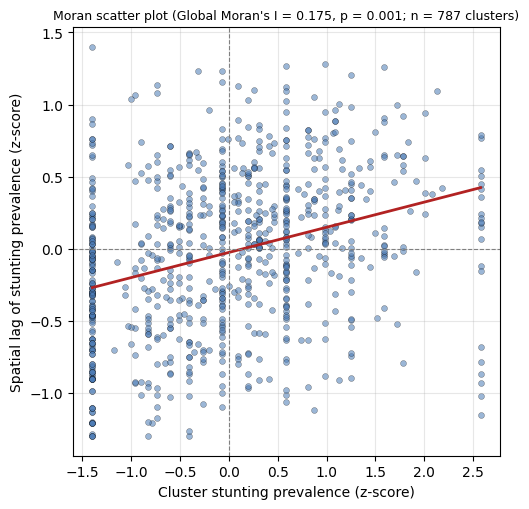

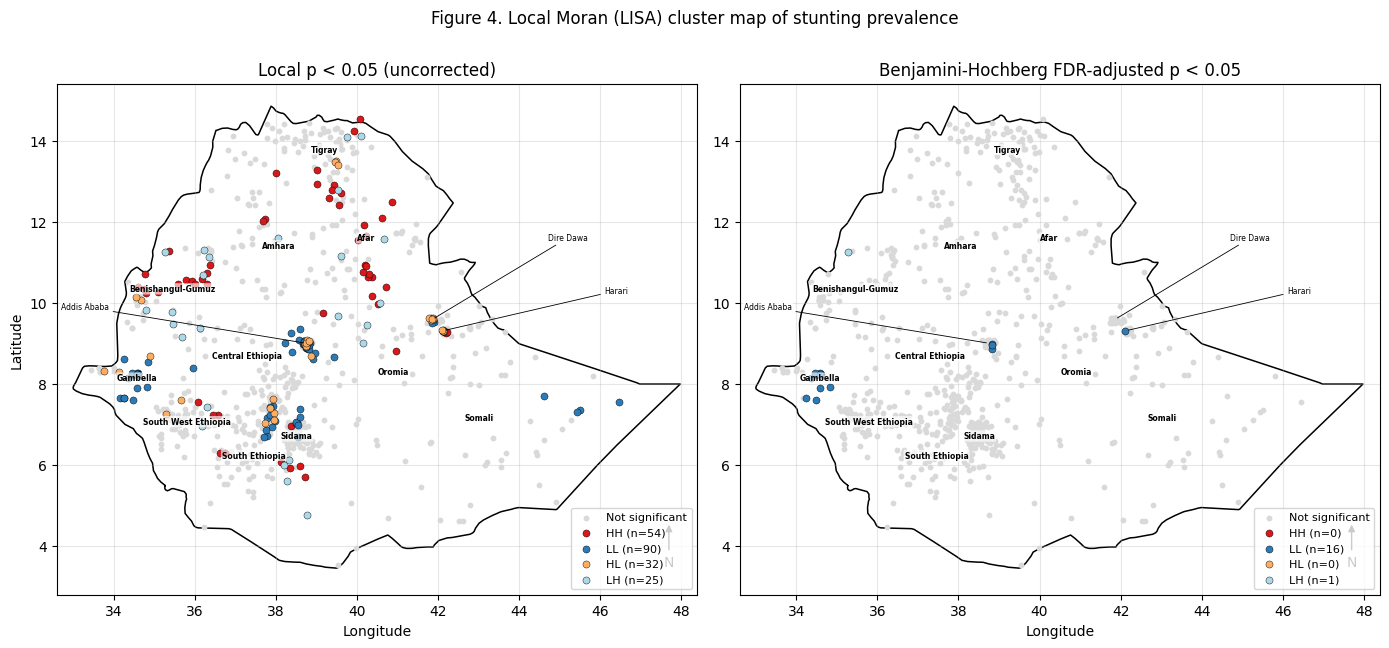

In [17]:
def knn_w(xy, k=6):
    t = cKDTree(xy); _, ind = t.query(xy, k=k+1); n = len(xy); W = np.zeros((n, n))
    for i in range(n): W[i, ind[i, 1:]] = 1.0/k
    return W
def n_components(W):
    from scipy.sparse.csgraph import connected_components; from scipy.sparse import csr_matrix
    return connected_components(csr_matrix(((W + W.T) > 0).astype(int)), directed=False)[0]
def moran(zv, W, perms=NPERM, seed=SEED):
    z = zv - zv.mean(); I = (z @ (W @ z))/(z @ z); r = np.random.default_rng(seed); sim = np.array([(lambda zp: (zp @ (W @ zp))/(zp @ zp))(r.permutation(z)) for _ in range(perms)])
    return float(I), float((1 + (sim >= I).sum())/(perms + 1))
def lisa(zv, W, perms=NPERM, seed=SEED):
    z = (zv - zv.mean())/zv.std(ddof=0); n = len(z); lag = W @ z; Ii = z*lag; r = np.random.default_rng(seed); p = np.empty(n)
    for i in range(n):
        others = np.delete(np.arange(n), i); nz = np.where(W[i] > 0)[0]; wv = W[i, nz]
        sims = np.array([z[i]*(wv @ z[r.choice(others, len(nz), replace=False)]) for _ in range(perms)])
        p[i] = (1 + (sims >= Ii[i]).sum())/(perms + 1) if Ii[i] > 0 else (1 + (sims <= Ii[i]).sum())/(perms + 1)
    q = np.where((z > 0) & (lag > 0), 'HH', np.where((z < 0) & (lag < 0), 'LL', np.where((z > 0) & (lag <= 0), 'HL', 'LH')))
    return Ii, p, q, z, lag
def bh_fdr(p):
    n = len(p); o = np.argsort(p); adj = np.minimum.accumulate((p[o]*n/np.arange(1, n+1))[::-1])[::-1]; out = np.empty(n); out[o] = np.minimum(adj, 1); return out

cc = cl.merge(cn.reset_index().rename(columns={'v001': 'DHSCLUST'}), on='DHSCLUST', how='left')
rows = []
for label, minn in [('All clusters with >=1 child', 1), ('Clusters with >=5 children', 5), ('Clusters with >=10 children', 10)]:
    sub = cc[cc.n >= minn].reset_index(drop=True); W = knn_w(sub[['LONGNUM', 'LATNUM']].values); I, pv = moran(sub.prev.values, W)
    Ii, p, q, z, lag = lisa(sub.prev.values, W); padj = bh_fdr(p); sg = p < .05; sf = padj < .05
    rows.append(dict(analysis=label, clusters=len(sub), moran_I=round(I, 3), moran_p=pv, disconnected_components=int(n_components(W)), expected_false_positives_5pct=round(.05*len(sub), 1),
        sig_uncorrected=int(sg.sum()), HH_unc=int(((q=='HH')&sg).sum()), LL_unc=int(((q=='LL')&sg).sum()), outliers_unc=int((((q=='HL')|(q=='LH'))&sg).sum()),
        sig_FDR=int(sf.sum()), HH_FDR=int(((q=='HH')&sf).sum()), LL_FDR=int(((q=='LL')&sf).sum()), outliers_FDR=int((((q=='HL')|(q=='LH'))&sf).sum())))
    if minn == 1: S = sub.assign(q=q, p=p, padj=padj, z=z, lag=lag)
display(save_table(pd.DataFrame(rows), 'Table_5_LISA_multiple_testing'))

# Moran scatter (properly standardised) and LISA maps
fig, ax = plt.subplots(figsize=(5.2, 5.2)); ax.scatter(S.z, S.lag, s=18, alpha=.55, edgecolor='k', linewidth=.3, color='#4a7ab5')
b = np.polyfit(S.z, S.lag, 1); xs = np.array([S.z.min(), S.z.max()]); ax.plot(xs, b[0]*xs + b[1], color='firebrick', lw=2); ax.axhline(0, color='gray', ls='--', lw=.8); ax.axvline(0, color='gray', ls='--', lw=.8)
ax.set_xlabel('Cluster stunting prevalence (z-score)'); ax.set_ylabel('Spatial lag of stunting prevalence (z-score)')
ax.set_title(f"Moran scatter plot (Global Moran's I = {rows[0]['moran_I']:.3f}, p = {rows[0]['moran_p']:.3f}; n = {rows[0]['clusters']} clusters)", fontsize=9); save_fig('Fig3_moran_scatter')

col = {'HH': '#d7191c', 'LL': '#2c7bb6', 'HL': '#fdae61', 'LH': '#abd9e9'}
Sreg = S.rename(columns={'LONGNUM': 'lon', 'LATNUM': 'lat', 'DHSREGNA': 'region'})
fig, axs = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, key, ttl in [(axs[0], 'p', 'Local p < 0.05 (uncorrected)'), (axs[1], 'padj', 'Benjamini-Hochberg FDR-adjusted p < 0.05')]:
    draw_eth(ax, Sreg, fs=5.5)
    ns = Sreg[Sreg[key] >= .05]; ax.scatter(ns.lon, ns.lat, s=10, color='#d9d9d9', zorder=3, label='Not significant')
    for qq in ['HH', 'LL', 'HL', 'LH']:
        t = Sreg[(Sreg[key] < .05) & (Sreg.q == qq)]; ax.scatter(t.lon, t.lat, s=26, color=col[qq], edgecolor='k', linewidth=.3, zorder=4, label=f'{qq} (n={len(t)})')
    ax.set_title(ttl); ax.set_xlabel('Longitude'); ax.legend(loc='lower right', fontsize=8); north_arrow(ax)
axs[0].set_ylabel('Latitude'); fig.suptitle('Figure 4. Local Moran (LISA) cluster map of stunting prevalence', y=.99); save_fig('Fig4_LISA_maps_uncorrected_vs_FDR')

In [18]:
# Optional cross-check against PySAL (esda/libpysal)
try:
    from libpysal.weights import KNN; from esda.moran import Moran
    sub = cc[cc.n >= 1].reset_index(drop=True); wk = KNN.from_array(sub[['LONGNUM', 'LATNUM']].values, k=6); wk.transform = 'r'
    mi = Moran(sub.prev.values, wk, permutations=NPERM); print(f'PySAL Moran I = {mi.I:.4f}, p_sim = {mi.p_sim:.4f}  (should match the value above)')
except Exception as e: print('PySAL cross-check skipped:', e)

PySAL Moran I = 0.1746, p_sim = 0.0010  (should match the value above)


## 10. Feature importance  *(Reviewer 1, comment 5)*
The **reported** importance is the Gini (mean-decrease-in-impurity) importance of the random forest fitted to all data. Because Gini importance favours continuous, high-cardinality predictors and is computed in-sample, we add **permutation importance on held-out spatial folds** (drop in AUC). SHAP is optional and supplementary only. None of these measures identifies causal drivers.

,gini,gini_rank,heldout_permutation_AUC_drop,permutation_rank
hw1,0.2351,1.0,0.1019,1.0
v190,0.0756,2.0,0.0202,2.0
v106,0.0622,3.0,0.0140,3.0
All_Population_Count_2020,0.0315,4.0,0.0015,7.0
Travel_Times,0.0311,5.0,-0.0008,26.0
UN_Population_Density_2020,0.0310,6.0,-0.0015,32.0
U5_Population_2020,0.0295,7.0,-0.0001,19.0
Nightlights_Composite,0.0267,8.0,-0.0008,25.0
Global_Human_Footprint,0.0252,9.0,0.0020,5.0
ITN_Coverage_2020,0.0251,10.0,0.0004,15.0


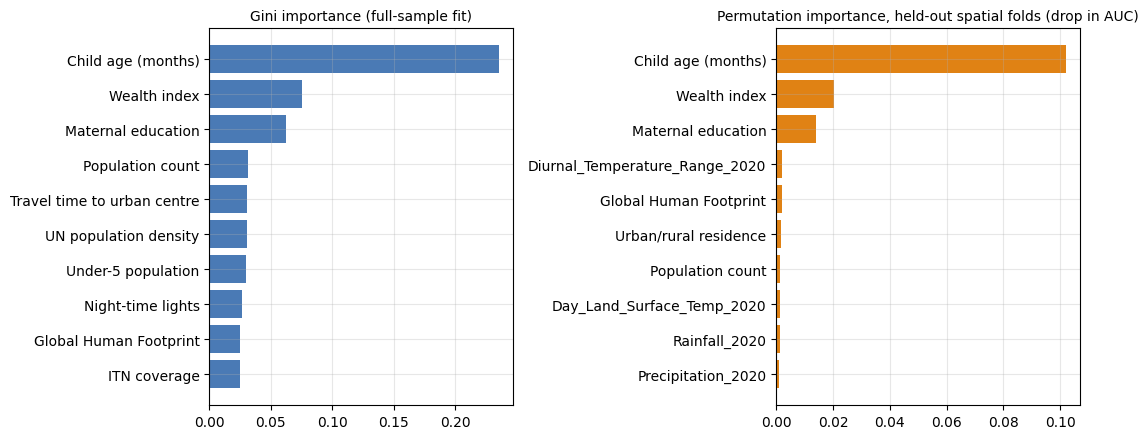

In [19]:
LAB = {'hw1': 'Child age (months)', 'v190': 'Wealth index', 'v106': 'Maternal education', 'v025': 'Urban/rural residence', 'Travel_Times': 'Travel time to urban centre', 'All_Population_Count_2020': 'Population count', 'UN_Population_Density_2020': 'UN population density', 'Global_Human_Footprint': 'Global Human Footprint', 'ITN_Coverage_2020': 'ITN coverage', 'U5_Population_2020': 'Under-5 population', 'Nightlights_Composite': 'Night-time lights', 'Livestock_Sheep': 'Sheep density'}
gini = pd.Series(full_model[-1].feature_importances_, index=X.columns).sort_values(ascending=False)
perm = pd.DataFrame(index=X.columns, columns=range(5), dtype=float)
for i, (tr, te) in enumerate(SCH['Spatial block (k=10)']):
    mm = make('Random forest').fit(X.iloc[tr], y[tr]); perm[i] = permutation_importance(mm, X.iloc[te], y[te], scoring='roc_auc', n_repeats=5 if not FAST else 2, random_state=SEED, n_jobs=1).importances_mean
pm = perm.mean(axis=1).sort_values(ascending=False)
imp = pd.DataFrame({'gini': gini, 'gini_rank': gini.rank(ascending=False), 'heldout_permutation_AUC_drop': pm, 'permutation_rank': pm.rank(ascending=False)}).sort_values('gini', ascending=False)
display(save_table(imp.round(4), 'Table_S9_feature_importance', index=True).head(15))
top = imp.head(10)[::-1]; fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
axs[0].barh([LAB.get(i, i) for i in top.index], top.gini, color='#4a7ab5'); axs[0].set_title('Gini importance (full-sample fit)', fontsize=10)
t2 = pm.head(10)[::-1]; axs[1].barh([LAB.get(i, i) for i in t2.index], t2.values, color='#e08214'); axs[1].set_title('Permutation importance, held-out spatial folds (drop in AUC)', fontsize=10); save_fig('Fig7_feature_importance')

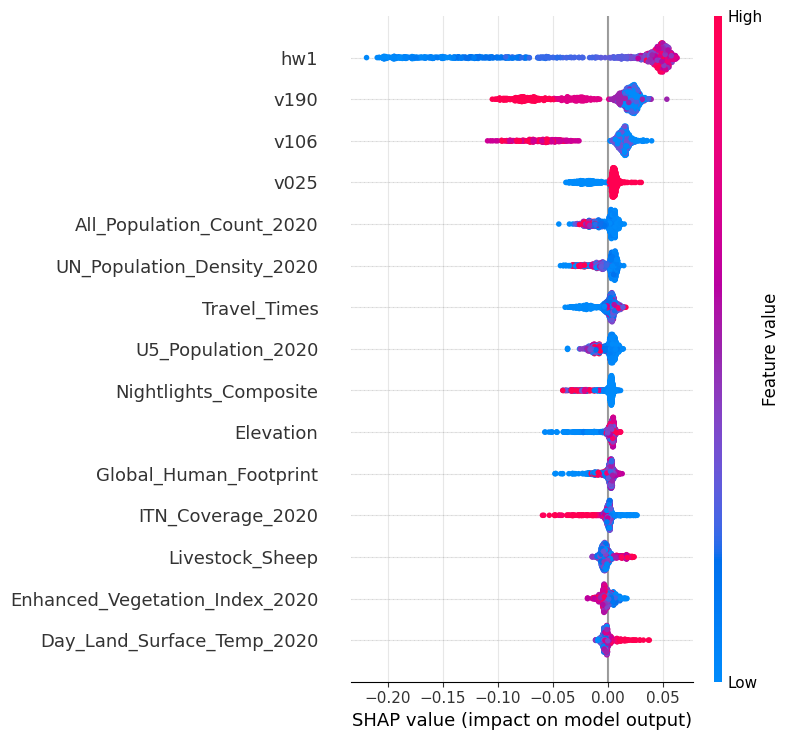

In [20]:
# Optional: SHAP (supplementary only; not used for any reported ranking)
if HAVE_SHAP:
    try:
        imp_ = full_model[0]; rf_ = full_model[-1]; Xi = pd.DataFrame(imp_.transform(X), columns=X.columns)
        sv = shap.TreeExplainer(rf_).shap_values(Xi.sample(1000, random_state=SEED)); sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if getattr(sv, 'ndim', 2) == 3 else sv)
        shap.summary_plot(sv, Xi.sample(1000, random_state=SEED), show=False, max_display=15); save_fig('FigS_SHAP_summary')
    except Exception as e: print('SHAP skipped:', e)

## 10b. Summary of all numbers and figures cited in the manuscript

In [21]:
print('='*100); print('NUMBERS CITED IN THE MANUSCRIPT (computed in this run)'); print('='*100)
print('Sample flow:'); display(flow)
print(f"Analytical sample: {len(d):,} children in {RES['clusters_used']} of {RES['clusters_gps']} clusters; median {RES['cluster_median_n']:.0f} children/cluster (IQR {RES['cluster_iqr'][0]:.0f}-{RES['cluster_iqr'][1]:.0f}); <5 children: {int((cn.n<5).sum())}; >=10: {int((cn.n>=10).sum())}")
print(f'Stunting prevalence: unweighted {100*pu:.1f}% (95% CI {100*(pu-1.96*seu):.1f}-{100*(pu+1.96*seu):.1f}); survey-weighted {100*pw:.1f}% (95% CI {100*(pw-1.96*sew):.1f}-{100*(pw+1.96*sew):.1f})')
print('\nTable 1/2 - cross-validated AUC (mean ± SD):'); display(tab.round(3))
print('\nRF - LR pooled out-of-fold AUC difference: %.3f (95%% CI %.3f to %.3f); RF better in %d of %d K-means seeds' % (*RES['rf_lr_diff'], int((sens['difference'] > 0).sum()), len(sens)))
print('\nTable 3 - classification metrics:'); display(ctab.round(3))
print(f"Out-of-fold PR-AUC {RES['ap']:.3f} (prevalence {RES['prev']:.3f}); Brier {RES['brier']:.3f}; calibration slope {RES['cal_slope']:.2f}, intercept {RES['cal_int']:.2f}")
print('\nTable 4 - feature sets:'); display(pd.read_csv(os.path.join(OUT_DIR, 'Table_4_feature_set_comparison.csv')))
print('\nTable 5 - Moran / LISA:'); display(pd.DataFrame(rows))
print('\nTop-10 importance (Gini vs held-out permutation):'); display(imp.head(10).round(4))
print('\nFIGURE FILES WRITTEN:'); [print('  ', f) for f in sorted(os.listdir(OUT_DIR)) if f.startswith('Fig') and f.endswith('.png')]

NUMBERS CITED IN THE MANUSCRIPT (computed in this run)
Sample flow:


,Step,Excluded / n,Remaining
0,Births in Children's Recode,13565,NaN
1,Not alive at interview,644,12921.0
2,Alive but not in the anthropometry subsample,6647,6274.0
3,In subsample but no HAZ recorded (absent/ref...,347,5927.0
4,HAZ flagged / biologically implausible (outs...,84,5843.0
5,Final analytical sample (children 0-59 months),5843,5843.0


Analytical sample: 5,843 children in 787 of 797 clusters; median 7 children/cluster (IQR 5-9); <5 children: 192; >=10: 196
Stunting prevalence: unweighted 37.7% (95% CI 36.5-39.0); survey-weighted 39.9% (95% CI 37.5-42.2)

Table 1/2 - cross-validated AUC (mean ± SD):


scheme,Cluster-grouped random,Random (child-level),Spatial block (k=10),Delta random-spatial,Delta random-cluster
model,,,,,
Random forest,0.687 ± 0.015,0.717 ± 0.015,0.670 ± 0.028,0.047,0.030
Logistic regression,0.680 ± 0.012,0.684 ± 0.017,0.665 ± 0.029,0.018,0.003
XGBoost,0.694 ± 0.010,0.720 ± 0.010,0.656 ± 0.030,0.064,0.026
Gradient boosting,0.694 ± 0.011,0.724 ± 0.012,0.656 ± 0.032,0.068,0.030
LightGBM,0.692 ± 0.005,0.719 ± 0.012,0.655 ± 0.022,0.064,0.027
KNN (spatial-only),0.602 ± 0.008,0.618 ± 0.014,0.566 ± 0.054,0.052,0.016



RF - LR pooled out-of-fold AUC difference: -0.005 (95% CI -0.019 to 0.010); RF better in 2 of 20 K-means seeds

Table 3 - classification metrics:


,setting,threshold,sensitivity,specificity,PPV,NPV,accuracy,TP,FP,TN,FN
0,"Out-of-fold (spatial CV), threshold 0.5 [pre-s...",0.500,0.631,0.613,0.497,0.733,0.620,1390,1409,2230,814
1,"Out-of-fold (spatial CV), prevalence-matched t...",0.547,0.505,0.700,0.504,0.700,0.626,1112,1093,2546,1092
2,"Out-of-fold (spatial CV), Youden threshold [po...",0.442,0.762,0.504,0.482,0.778,0.601,1680,1805,1834,524
3,"In-sample (model re-fitted to all 5,843 childr...",0.500,0.801,0.644,0.577,0.843,0.704,1766,1294,2345,438


... (4 outputs left out)


Top-10 importance (Gini vs held-out permutation):


,gini,gini_rank,heldout_permutation_AUC_drop,permutation_rank
hw1,0.2351,1.0,0.1019,1.0
v190,0.0756,2.0,0.0202,2.0
v106,0.0622,3.0,0.0140,3.0
All_Population_Count_2020,0.0315,4.0,0.0015,7.0
Travel_Times,0.0311,5.0,-0.0008,26.0
UN_Population_Density_2020,0.0310,6.0,-0.0015,32.0
U5_Population_2020,0.0295,7.0,-0.0001,19.0
Nightlights_Composite,0.0267,8.0,-0.0008,25.0
Global_Human_Footprint,0.0252,9.0,0.0020,5.0
ITN_Coverage_2020,0.0251,10.0,0.0004,15.0



FIGURE FILES WRITTEN:
   Fig1_study_area_clusters_by_region.png
   Fig2_cluster_prevalence_map.png
   Fig3_moran_scatter.png
   Fig4_LISA_maps_uncorrected_vs_FDR.png
   Fig5_cv_comparison.png
   Fig6_confusion_matrices.png
   Fig7_feature_importance.png
   Fig8_spatial_folds.png
   Fig9_precision_recall_calibration.png
   FigS_SHAP_summary.png


[None, None, None, None, None, None, None, None, None, None]

## 11. Shareable outputs
Only aggregated, non-identifiable results are exported (tables and figures above plus a cluster-level summary **without coordinates**). Child-level data and DHS GPS files must not be redistributed.

In [22]:
agg = cn.reset_index().rename(columns={'v001': 'cluster_id', 'n': 'children_with_valid_HAZ', 'k': 'stunted_children', 'prev': 'unweighted_prevalence'})
save_table(agg, 'cluster_level_summary_no_coordinates')
summary = dict(n_children=int(len(d)), n_clusters=int(d.v001.nunique()), prevalence_unweighted=float(pu), prevalence_weighted=float(pw), seed=SEED, fast_mode=FAST)
json.dump(summary, open(os.path.join(OUT_DIR, 'run_summary.json'), 'w'), indent=1)
print('Finished. Files written to', OUT_DIR); print(sorted(os.listdir(OUT_DIR)))

Finished. Files written to /content/drive/MyDrive/Stunting_Geospatial/outputs
['Fig1_study_area_clusters_by_region.png', 'Fig2_cluster_prevalence_map.png', 'Fig3_moran_scatter.png', 'Fig4_LISA_maps_uncorrected_vs_FDR.png', 'Fig5_cv_comparison.png', 'Fig6_confusion_matrices.png', 'Fig7_feature_importance.png', 'Fig8_spatial_folds.png', 'Fig9_precision_recall_calibration.png', 'FigS_SHAP_summary.png', 'Table_1_2_cv_schemes.csv', 'Table_3_classification_metrics.csv', 'Table_4_feature_set_comparison.csv', 'Table_5_LISA_multiple_testing.csv', 'Table_S1_sample_flow.csv', 'Table_S2_prevalence.csv', 'Table_S3_cluster_overlap.csv', 'Table_S4_spatial_fold_description.csv', 'Table_S5_hyperparameters.csv', 'Table_S6_kmeans_seed_sensitivity.csv', 'Table_S7_block_number_sensitivity.csv', 'Table_S8_calibration_deciles.csv', 'Table_S9_feature_importance.csv', 'cluster_level_summary_no_coordinates.csv', 'cv_summary_long.csv', 'environment_versions.json', 'run_summary.json']
